In [34]:
import math
import numpy as np
import tensorflow as tf

from plotly.subplots import make_subplots
import plotly.graph_objects as go

from optical_communication_system.components import *
from optical_communication_system.datatypes import ElectricalSignal, OpticalSignal
from optical_communication_system.utils import symbol_mapping_to_gray, dbm_to_w
from optical_communication_system.plot import *

In [35]:
Component.trace_debug_enabled_by_default = True

data_rate = 10e9
sampling_rate = data_rate * 10
central_frequency = 193.414e12 # Hz

input_power = 2e-3 # Watts

lpf = BandPassFilter(min_frequency=0.0, max_frequency=1 * data_rate, name="lpf")

qam4_mapping = tf.constant([
    [-1.0, -1.0], [-1.0, 1.0],
    [ 1.0, -1.0], [ 1.0, 1.0]
])

qam16_mapping = symbol_mapping_to_gray([
    [-1.0,  1.0], [-1.0,  1/3], [-1.0, -1/3], [-1.0, -1.0],
    [-1/3, -1.0], [-1/3, -1/3], [-1/3,  1/3], [-1/3,  1.0],
    [ 1/3,  1.0], [ 1/3,  1/3], [ 1/3, -1/3], [ 1/3, -1.0],
    [ 1.0, -1.0], [ 1.0, -1/3], [ 1.0,  1/3], [ 1.0,  1.0]
])

bits_per_symbol, symbol_mapping = 2, qam4_mapping

channel_osnr = 30.0

channel = Composition([
    OpticalAWGN(relative_db=-channel_osnr, name="channel_noise"),
    OpticalFiber(
        attenuation=0.22,
        length=40.0,
        chromatic_dispersion=17.0,
        eff_non_linear_coeff=1.76,
        central_frequency=central_frequency,
        step_count=1000,
        name="fiber"
    )
], name="channel")

input_laser = Laser(power=input_power, name="laser")
local_oscillator = Laser(power=1e-3)

photodiode = Composition([Photodiode(), Quantizer(step=1e-4), lpf])

transmitter = Composition([
    IQEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        symbol_encoder=IQSymbolEncoder(
            bits_per_symbol=bits_per_symbol,
            mapping=symbol_mapping,
            adjust_for_mzm=True,
            name="iq_symbol_encoder"
        )
    ),  # (ElectricalSignal, ElectricalSignal)
    MapComponents(lpf, name="encoder_output"),  # (ElectricalSignal, ElectricalSignal)
    IQModulator(carrier_source=input_laser, name="modulator")  # OpticalSignal
], name="transmitter")

iq_receiver = IQReceiver(
    photodiode=photodiode,
    local_oscillator=local_oscillator,
    name="receiver_output"
)

receiver = Composition([
    iq_receiver,  # (ElectricalSignal, ElectricalSignal)
    MapComponents(ElectricalGain(gain=1.0)),
    IQDecoder(
        data_rate=data_rate,
        symbol_decoder=IQSymbolDecoder(
            bits_per_symbol=bits_per_symbol,
            mapping=symbol_mapping,
            name="iq_symbol_decoder"
        ),
        name="decoder_output"
    )  # tf.TensorSpec(shape=[None, None, None], dtype=tf.int32)
])

system = Composition([transmitter, channel, receiver])
channel_loss_estimator = ChannelLossEstimator(
    laser=input_laser,
    photodiode=Composition([
        iq_receiver,
        Lambda(
            lambda x: ElectricalSignal(
                timing=x[0].timing,
                samples=(tf.abs(x[0].samples) + tf.abs(x[1].samples)) / (2 * 0.5 ** 0.5)
            )
        )
    ]),
    channel=channel,
    sampling_rate=1e9
)

rng = tf.random.Generator.from_non_deterministic_state(alg="philox")
ber_tester = BERTester(system)

In [63]:
input_signal = tf.constant([[1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1]], dtype=tf.int32)
input_signal = rng.uniform((1, 512), 0, 2, dtype=tf.int32)

data_rate = 10e9
sampling_rate = data_rate * 10
central_frequency = 193.414e12 # Hz

input_power = dbm_to_w(17.0)

bits_per_symbol, symbol_mapping = 4, qam16_mapping
channel_osnr = 40.0
cutoff_frequency = 4.0 * data_rate

system_params = dict(
    laser__power=input_power,
    photodiode__maximum_power=dbm_to_w(17.0),
    fiber__step_count=tf.constant(10000),
    fiber__length=tf.constant(120.0),
    fiber__eff_non_linear_coeff=tf.constant(1.76 * 100),
    fiber__chromatic_dispersion=tf.constant(17.0 * 0.1),
    iq_encoder__data_rate=tf.constant(data_rate),
    iq_encoder__sampling_rate=tf.constant(sampling_rate),
    decoder_output__data_rate=tf.constant(data_rate),
    iq_symbol_encoder__mapping=tf.constant(symbol_mapping),
    iq_symbol_decoder__mapping=tf.constant(symbol_mapping),
    iq_symbol_encoder__bits_per_symbol=tf.constant(bits_per_symbol),
    iq_symbol_decoder__bits_per_symbol=tf.constant(bits_per_symbol),
    channel_noise__relative_db=tf.constant(-channel_osnr),
    lpf__max_frequency=tf.constant(cutoff_frequency),
    quantizer__step=tf.constant(1e-6),
    batch_size=tf.shape(input_signal)[0],
    parameter_dims=tf.constant(1)
)

estimated_channel_loss = channel_loss_estimator(1000e-9, **system_params)[0]

symbol_scale = input_power / estimated_channel_loss
system_params["electrical_gain__gain"] = 1.0 / symbol_scale

%time system.trace(input_signal, **system_params)

Calling Composition(name='composition') with args tf.Tensor(shape=[  1 512], dtype=tf.int32)
|---Calling Composition(name='transmitter') with args tf.Tensor(shape=[  1 512], dtype=tf.int32)
|---|---Calling IQEncoder(name='iq_encoder') with args tf.Tensor(shape=[  1 512], dtype=tf.int32)
|---|---|---Calling IQSymbolEncoder(name='iq_symbol_encoder') with args tf.Tensor(shape=[  1 512], dtype=tf.int32)
|---|---|---|---Return tf.Tensor(shape=[  1   1 128   2], dtype=tf.float32)
|---|---|---Return tuple[ElectricalSignal[   1    1 5120], ElectricalSignal[   1    1 5120]]
|---|---Calling MapComponents(name='encoder_output') with args tuple[ElectricalSignal[   1    1 5120], ElectricalSignal[   1    1 5120]]
|---|---|---Calling BandPassFilter(name='lpf') with args ElectricalSignal[   1    1 5120]
|---|---|---|---Return ElectricalSignal[   1    1 5120]
|---|---|---Calling BandPassFilter(name='lpf') with args ElectricalSignal[   1    1 5120]
|---|---|---|---Return ElectricalSignal[   1    1 5120]

<tf.Tensor: shape=(1, 1, 512), dtype=int32, numpy=
array([[[0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1,
         1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1,
         0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
         1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1,
         0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
         0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1,
         0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0,
         0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1,
         1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1,
         1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1,
         0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0,
         1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0,
         1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0,
         0, 1

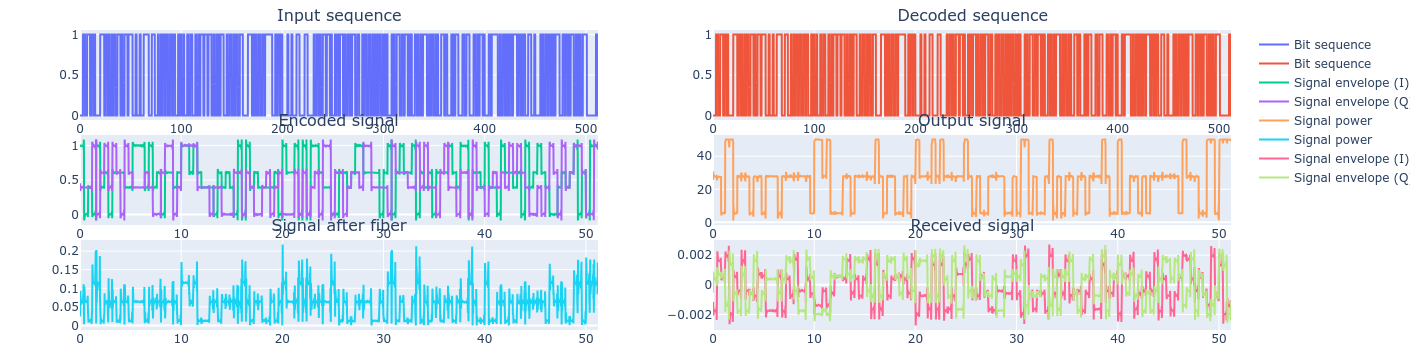

In [64]:
fig = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=(
        "Input sequence", "Decoded sequence",
        "Encoded signal", "Output signal",
        "Signal after fiber", "Received signal"
    ),
    vertical_spacing = 0.05
)

plot_bitseq(input_signal, fig, 0, row=1, col=1)
plot_bitseq(system.output, fig, row=1, col=2)
plot_envelope(system.find_child("encoder_output").output, fig, row=2, col=1)
plot_power(system.find_child("modulator").output, fig, row=2, col=2)
plot_power(system.find_child("channel").output, fig, row=3, col=1)

plot_envelope(system.find_child("receiver_output").output, fig, row=3, col=2)

fig.update_layout(
    autosize=True,
    height=1000,
    margin=dict(t=30, b=30)
)
fig.show()

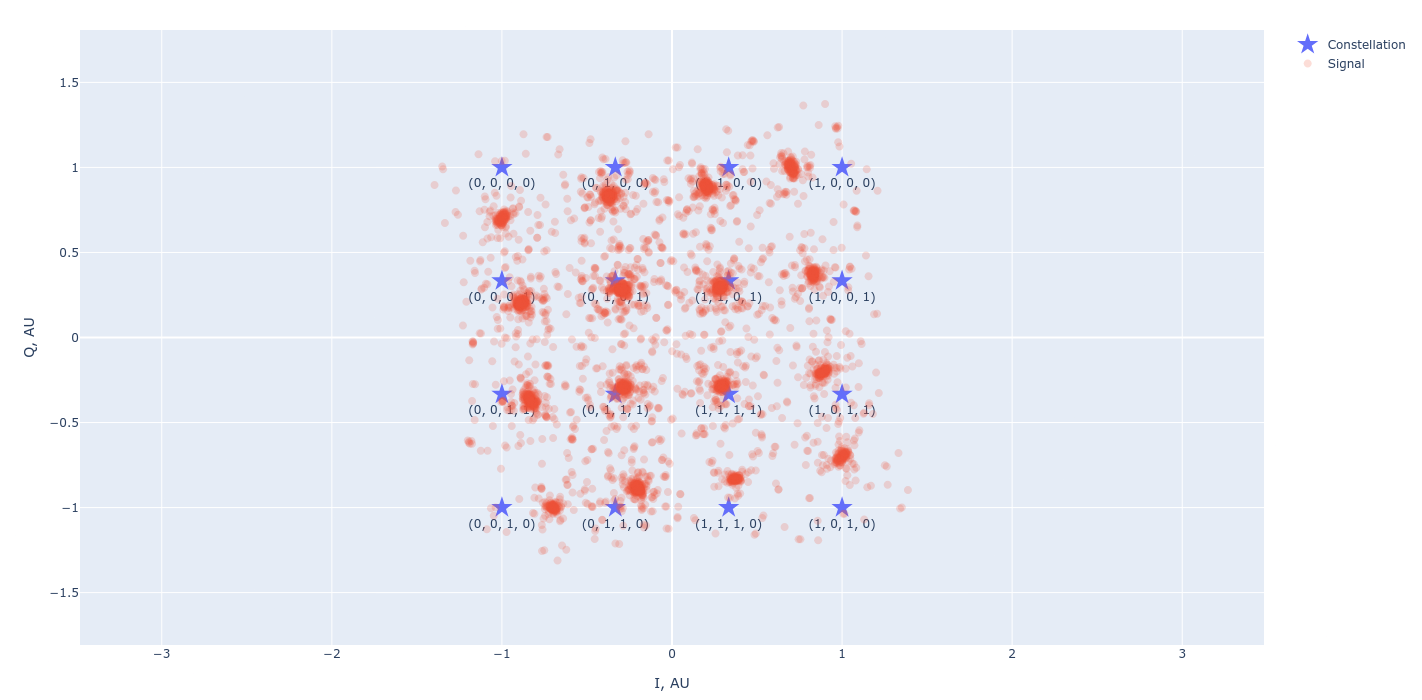

In [65]:
annotate_constellation = True
annotations = []

if annotate_constellation:
    for i, symbol in enumerate(symbol_mapping):
        bit_string = ', '.join(
            tuple(
                bin(i)[2:].zfill(
                    int(bits_per_symbol)
                )
            )
        )
    
        annotations.append(f"({bit_string})")

fig = plot_iq_constellation(
    tf.expand_dims(symbol_mapping, 0),
    label="Constellation",
    mode="markers+text",
    text=annotations,
    textposition="bottom center",
    marker=dict(size=16, symbol="star")
)

fig = plot_iq_constellation(
    system.find_child("receiver_output").output,
    fig,
    iq_units=(1 / symbol_scale, "AU"),
    label="Signal",
    marker=dict(size=8, opacity=0.2),
)

fig.update_yaxes(scaleanchor='x', range=[-1.5, 1.5])
fig.update_xaxes(range=[-1.5, 1.5])
fig.update_layout(width=800, height=700, margin=dict(t=30, b=30))
fig.show()

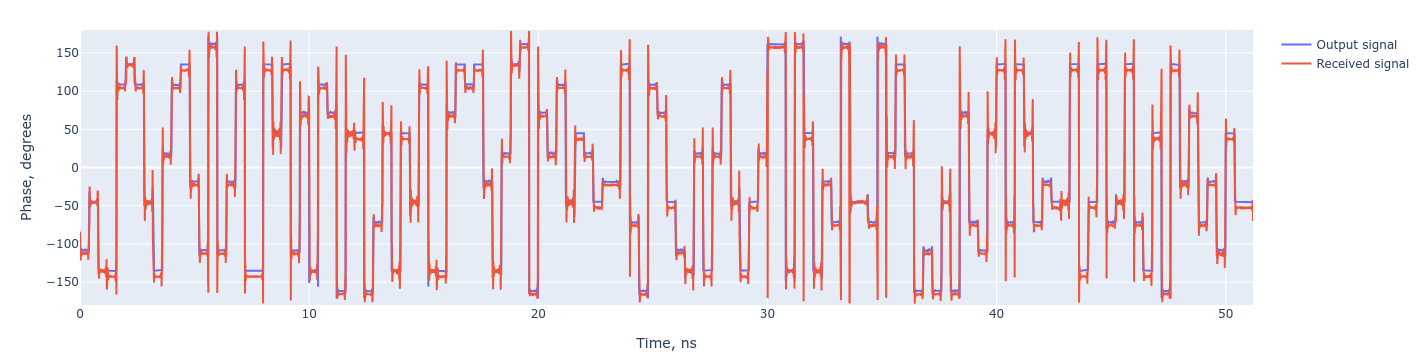

In [39]:
fig = plot_phase(system.find_child("modulator").output, label="Output signal")
plot_phase(system.find_child("receiver_output").output, fig, label="Received signal")

fig.update_yaxes(range=[-180.0, 180.0])
fig.update_layout(autosize=True, height=600, margin=dict(t=30, b=30))

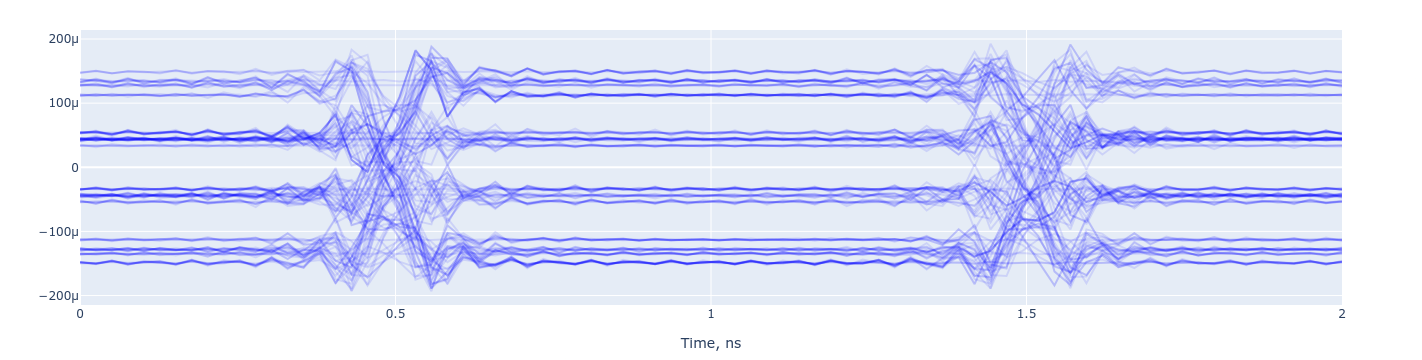

In [31]:
fig = go.Figure(layout=go.Layout(xaxis={"title": "Time, ns"}, showlegend=False))
for signal in system.find_child("receiver_output").output:
    plot_eye_diagram(signal, data_rate / bits_per_symbol, fig, line={"color": "rgba(0, 0, 255, 0.111)"})
fig.update_layout(autosize=True, height=600, margin=dict(t=30, b=30))
fig.show()

In [32]:
%time ber_tester(tf.constant(128), **system_params)

CPU times: user 39.6 s, sys: 1.36 s, total: 41 s
Wall time: 15 s


<tf.Tensor: shape=(1,), dtype=float32, numpy=array([0.], dtype=float32)>